<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Detecci%C3%B3n_de_Tomato_Leaf_Disease_Final_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;">  1 | Importing The Libraries</h1>
</div>

In [ ]:
import os  # Operating system interfaces
import tensorflow as tf                                    # TensorFlow deep learning framework
import matplotlib.pyplot as plt                            # Plotting library
import matplotlib.image as mpimg                           # Image loading and manipulation library
from tensorflow.keras.models import Sequential, Model      # Sequential and Functional API for building models
from tensorflow.keras.optimizers import Adam               # Adam optimizer for model training
from tensorflow.keras.callbacks import EarlyStopping       # Early stopping callback for model training
from tensorflow.keras.regularizers import l1, l2           # L1 and L2 regularization for model regularization
from tensorflow.keras.preprocessing.image import ImageDataGenerator  # Data augmentation and preprocessing for images
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D, AveragePooling2D, MaxPooling2D, BatchNormalization
# Various types of layers for building neural networks
from tensorflow.keras.applications import DenseNet121, EfficientNetB4, Xception, VGG16, VGG19   # Pre-trained models for transfer learning

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kaustubhb999/tomatoleaf")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'tomatoleaf' dataset.
Path to dataset files: /kaggle/input/tomatoleaf


<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;"> 2 | Loading The DataSet</h1>
</div>

In [ ]:
train_data = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/input/tomatoleaf/tomato/train',
    labels='inferred',
    label_mode='categorical',
    image_size=(256, 256),
    batch_size=32)

train_data = train_data.map(lambda x, y: (x / 255.0, y))

Found 10000 files belonging to 10 classes.


In [ ]:
val_data = tf.keras.preprocessing.image_dataset_from_directory(
    '/kaggle/input/tomatoleaf/tomato/val',
    labels='inferred',
    label_mode='categorical',
    image_size=(256, 256),
    batch_size=32)

val_data = val_data.map(lambda x, y: (x / 255.0, y))

Found 1000 files belonging to 10 classes.


<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;"> 3 | Visualizing The Data</h1>
</div>

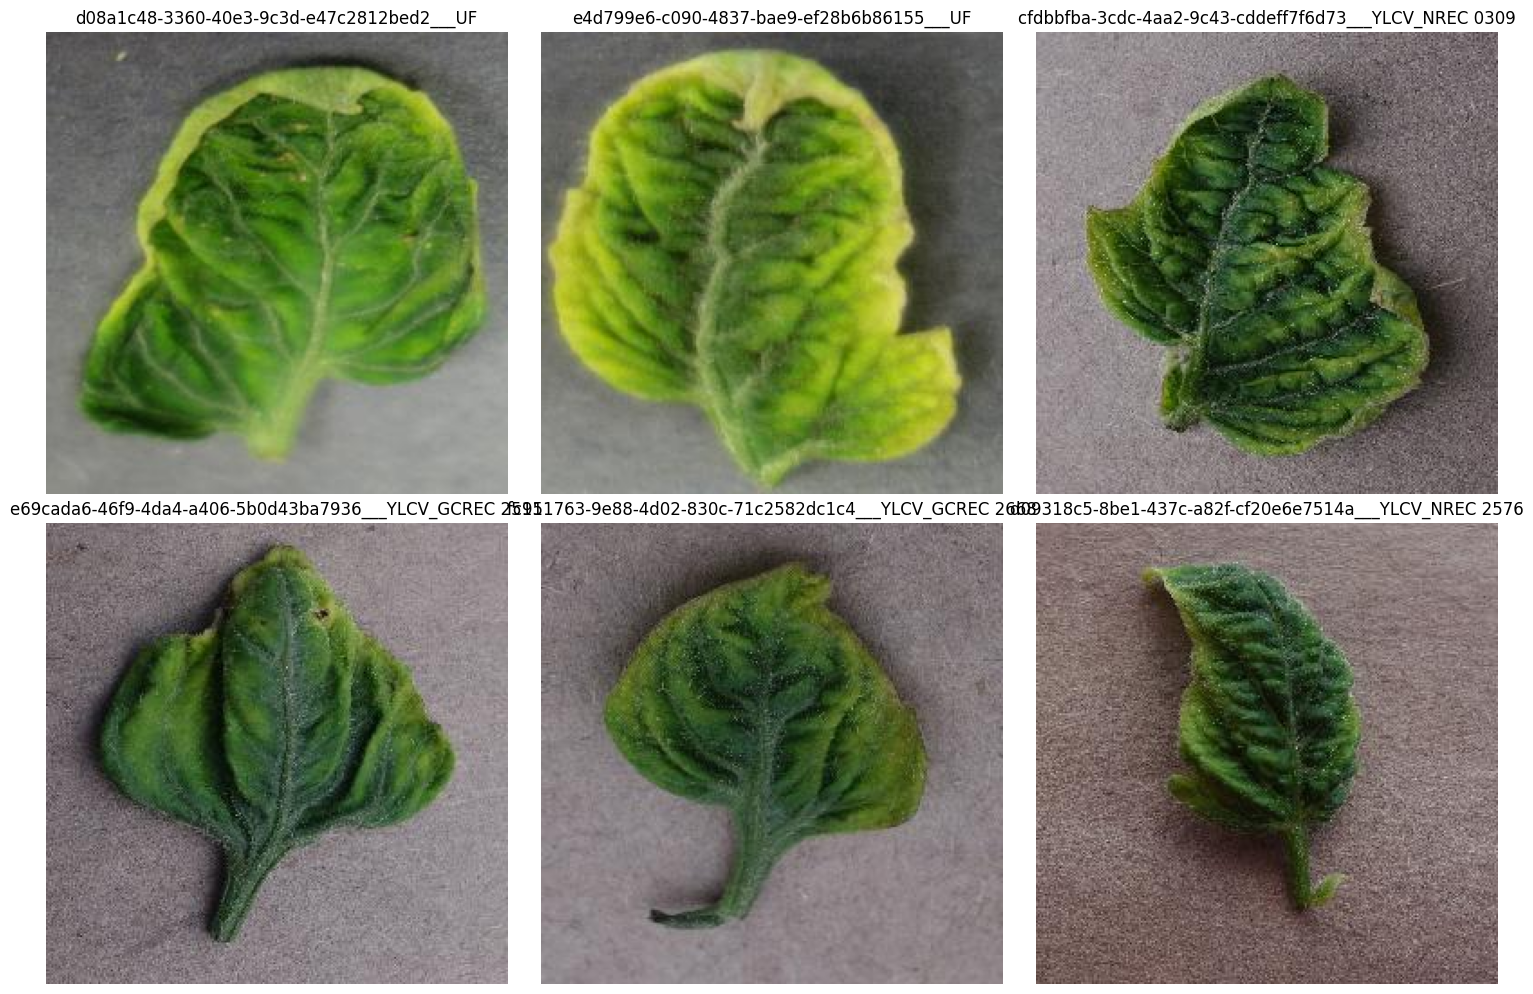

In [ ]:
# Path to the directory containing images
path = "/kaggle/input/tomatoleaf/tomato/train/Tomato___Tomato_Yellow_Leaf_Curl_Virus"

# Get a list of all image file names in the directory
image_files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]

# Display the first 6 images with their labels
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for i in range(6):
    # Get the image file name and its label
    image_file = image_files[i]
    label = image_file.split('.')[0]

    # Load and display the image
    img_path = os.path.join(path, image_file)
    img = mpimg.imread(img_path)
    ax = axs[i // 3, i % 3]
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(label)

plt.tight_layout()
plt.show()

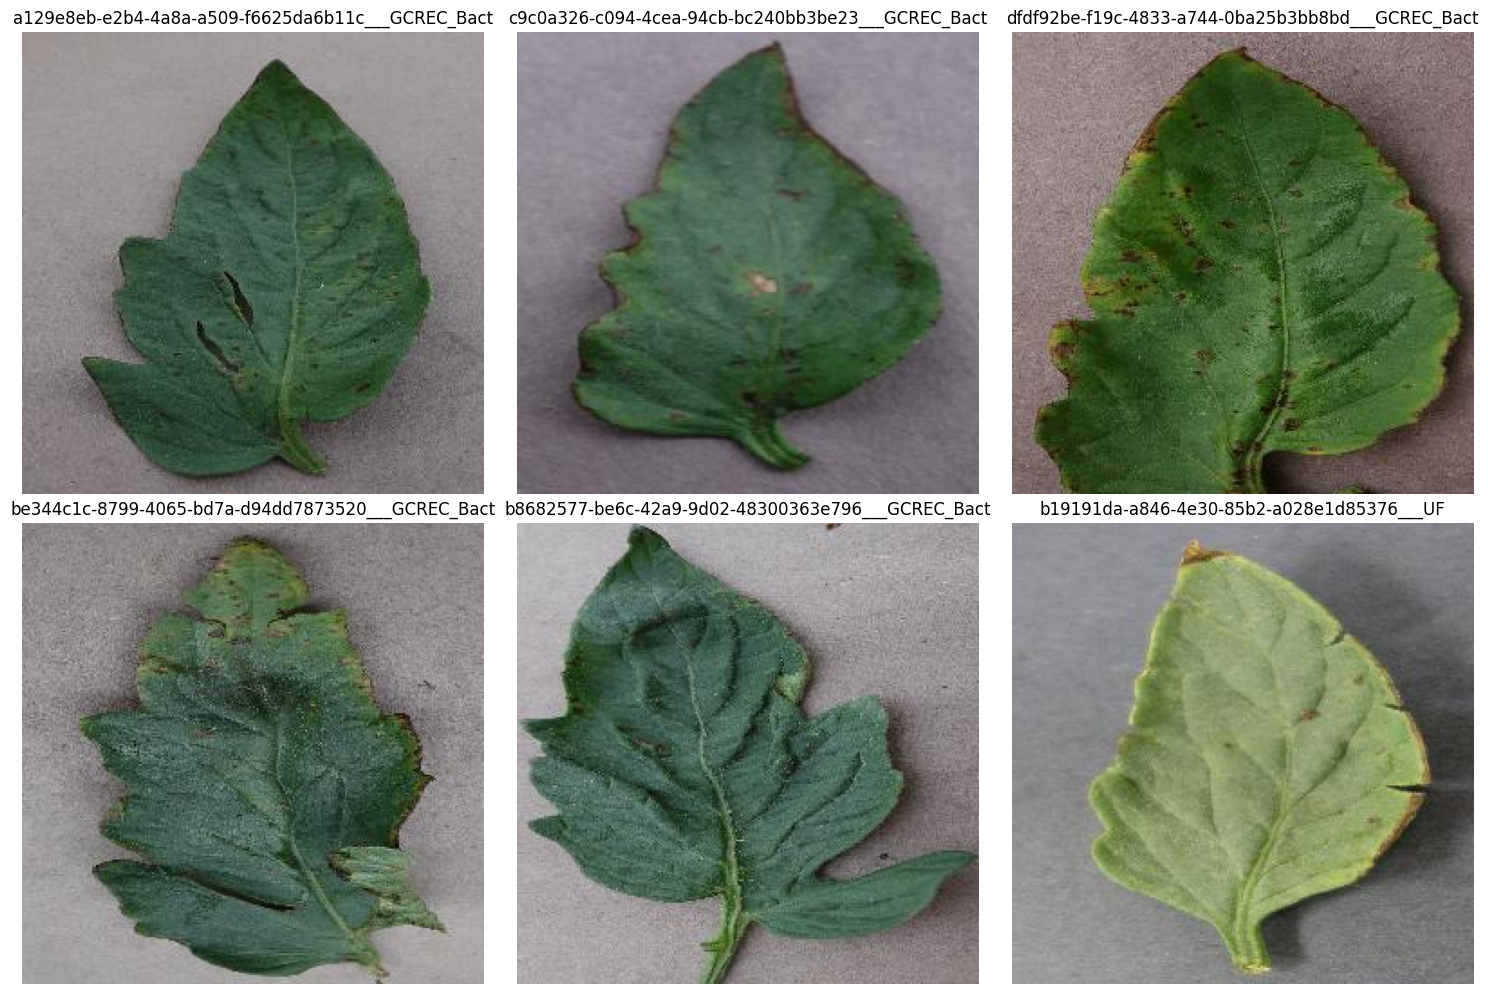

In [ ]:
# Path to the directory containing images
path = "/kaggle/input/tomatoleaf/tomato/train/Tomato___Bacterial_spot"

# Get a list of all image file names in the directory
image_files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]

# Display the first 6 images with their labels
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for i in range(6):
    # Get the image file name and its label
    image_file = image_files[i]
    label = image_file.split('.')[0]

    # Load and display the image
    img_path = os.path.join(path, image_file)
    img = mpimg.imread(img_path)
    ax = axs[i // 3, i % 3]
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(label)

plt.tight_layout()
plt.show()


<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;">4 | Training The Model</h1>
</div>

In [ ]:
conv_base = DenseNet121(
    weights='imagenet',
    include_top = False,
    input_shape=(256,256,3),
    pooling='avg'
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
conv_base.trainable = False

In [ ]:
model = Sequential()
model.add(conv_base)
model.add(BatchNormalization())
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.35))
model.add(BatchNormalization())
model.add(Dense(120, activation='relu'))
model.add(Dense(10, activation='softmax'))

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# history = model.fit(train_ds,epochs=10,validation_data=validation_ds)
history = model.fit(train_data, epochs=100, validation_data=val_data, callbacks=[EarlyStopping(patience=0)])

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 109s 220ms/step - accuracy: 0.5318 - loss: 1.4203 - val_accuracy: 0.7620 - val_loss: 0.9127
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.7798 - loss: 0.7046 - val_accuracy: 0.8390 - val_loss: 0.5255
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.8443 - loss: 0.5001 - val_accuracy: 0.8740 - val_loss: 0.4028
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.8783 - loss: 0.3907 - val_accuracy: 0.8910 - val_loss: 0.3368
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.8962 - loss: 0.3206 - val_accuracy: 0.9000 - val_loss: 0.2964
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.9133 - loss: 0.2751 - val_accuracy: 0.9130 - val_loss: 0.2674
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.9253 - loss: 0.2369 - val_accuracy: 0.9190 - val_loss: 0.2389
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.9337 - loss:

In [ ]:
# Evaluate the model on the validation data
evaluation = model.evaluate(val_data)

# Print the evaluation metrics
print("Validation Loss:", evaluation[0])
print("Validation Accuracy:", evaluation[1])

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9500 - loss: 0.1494
Validation Loss: 0.1493506282567978
Validation Accuracy: 0.949999988079071


Found 1000 files belonging to 10 classes.
1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


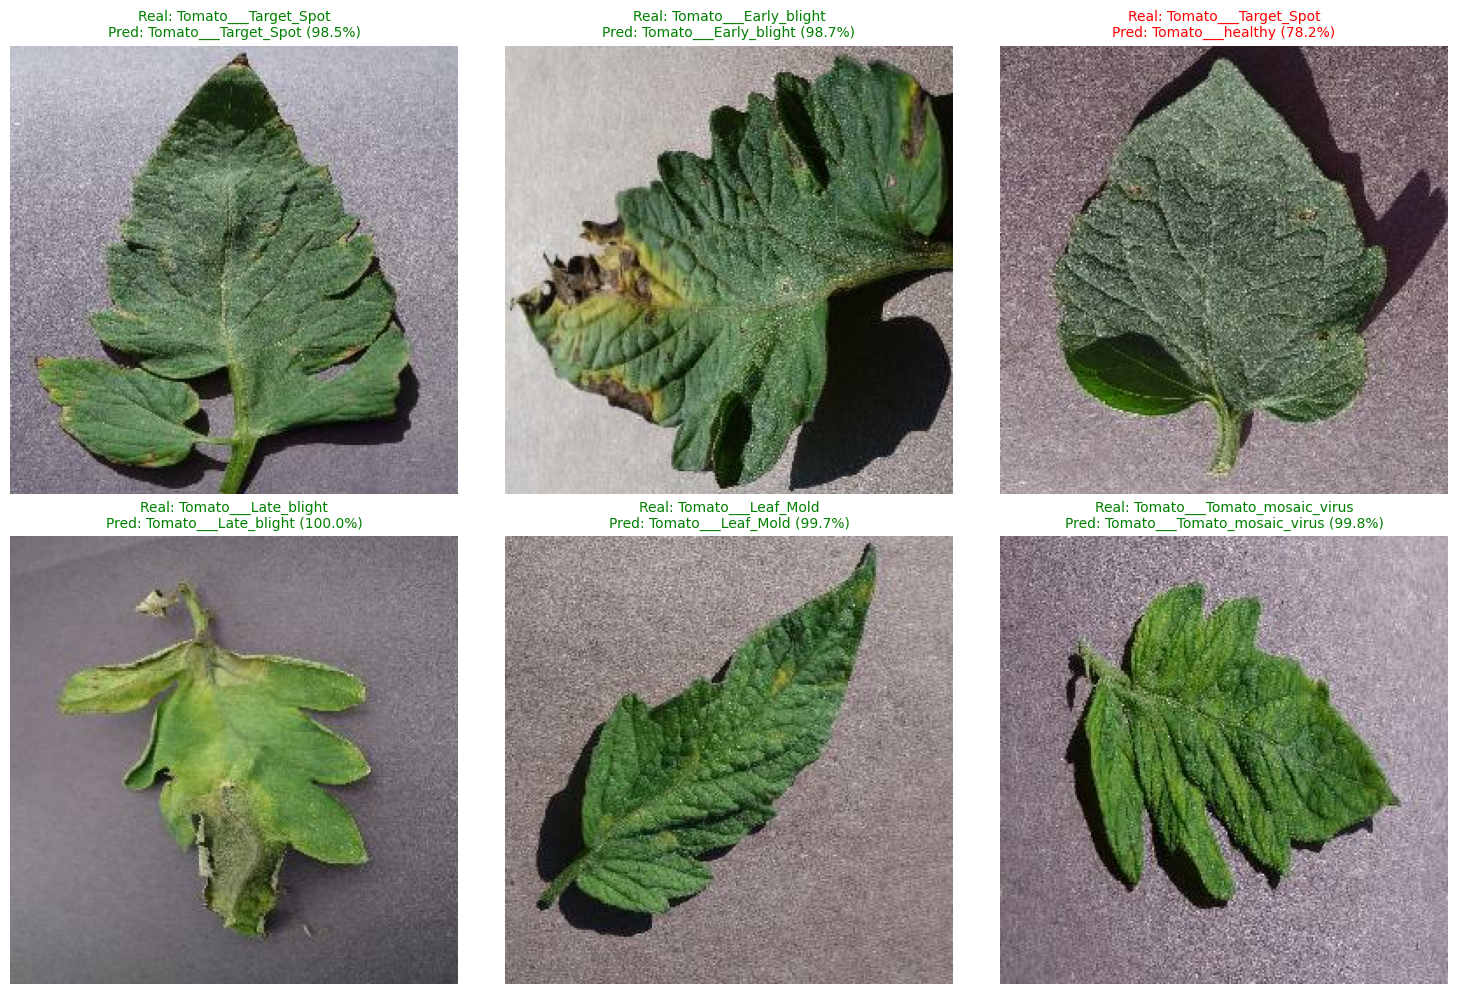

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el dataset de test
test_data = tf.keras.preprocessing.image_dataset_from_directory(
    '/kaggle/input/tomatoleaf/tomato/val', # Usamos val como test en este set de datos si no hay carpeta test explícita
    labels='inferred',
    label_mode='categorical',
    image_size=(256, 256),
    batch_size=32,
    shuffle=True
)

# Obtener nombres de las clases
class_names = test_data.class_names

# Normalizar las imágenes de test
test_data_normalized = test_data.map(lambda x, y: (x / 255.0, y))

# 2. Tomar un lote (batch) de imágenes para predecir
for images, labels in test_data_normalized.take(1):
    predictions = model.predict(images)

    # Mostrar las primeras 6 imágenes con sus predicciones
    plt.figure(figsize=(15, 10))
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy())

        actual_class = class_names[np.argmax(labels[i])]
        predicted_class = class_names[np.argmax(predictions[i])]
        confidence = np.max(predictions[i]) * 100

        title_color = 'green' if actual_class == predicted_class else 'red'
        plt.title(f"Real: {actual_class}\nPred: {predicted_class} ({confidence:.1f}%)", color=title_color, fontsize=10)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

Imagen seleccionada para clasificar: 0c676b36-7985-42e8-b550-83e2b1c55535___PSU_CG 2177.JPG
Clase real: Tomato___Tomato_mosaic_virus
1/1 ━━━━━━━━━━━━━━━━━━━━ 19s 19s/step


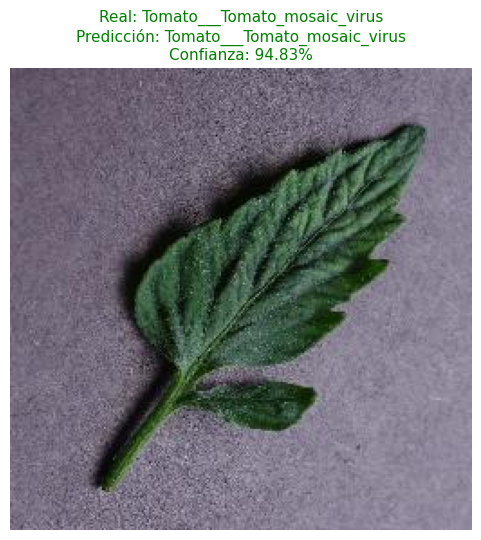

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import random

# 1. Seleccionar de forma aleatoria una carpeta de enfermedad y una de sus imágenes del set de validación (test)
val_dir = '/kaggle/input/tomatoleaf/tomato/val'
enfermedades = [d for d in os.listdir(val_dir) if os.path.isdir(os.path.join(val_dir, d))]
enfermedad_elegida = random.choice(enfermedades)
ruta_enfermedad = os.path.join(val_dir, enfermedad_elegida)

imagenes = [img for img in os.listdir(ruta_enfermedad) if img.lower().endswith(('.png', '.jpg', '.jpeg'))]
imagen_elegida = random.choice(imagenes)
ruta_imagen_completa = os.path.join(ruta_enfermedad, imagen_elegida)

print(f"Imagen seleccionada para clasificar: {imagen_elegida}")
print(f"Clase real: {enfermedad_elegida}")

# 2. Cargar y preprocesar la imagen como si viniera de fuera
img = tf.keras.utils.load_img(
    ruta_imagen_completa,
    target_size=(256, 256)
)
img_array = tf.keras.utils.img_to_array(img)
img_array = img_array / 255.0  # Normalización igual que en el entrenamiento
img_array = np.expand_dims(img_array, axis=0)  # Crear dimensión de lote

# 3. Realizar la predicción con el modelo entrenado
predictions = model.predict(img_array)
predicted_class_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_class_index]
confidence = predictions[0][predicted_class_index] * 100

# 4. Mostrar la imagen original con el resultado de la predicción
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title(f"Real: {enfermedad_elegida}\nPredicción: {predicted_class}\nConfianza: {confidence:.2f}%", fontsize=11, color='green' if enfermedad_elegida == predicted_class else 'red')
plt.axis('off')
plt.show()